# HR Analytics — Python Cleaning & EDA

This notebook does the deeper cleaning and exploratory analysis that Excel isn't well suited for, and answers the business questions from Part 1.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
print("Libraries loaded")

Libraries loaded


## 2. Load Data

In [1]:
df = pd.read_csv('../01_raw_data/HR_raw_data.csv')
print(df.shape)

(50000, 40)


## 3. Understand Data

Basic look at the columns and data types before doing anything else.

In [1]:
print(df.dtypes)

EmployeeID                      int64
DateOfHire                        str
DateOfBirth                       str
Gender                            str
Department                        str
JobTitle                          str
EmploymentStatus                  str
SupervisorID                    int64
SupervisorName                    str
SupervisorLevel                   str
ProjectsAssigned                int64
ProjectsCompleted               int64
PerformanceRating               int64
Salary                        float64
Bonus                         float64
YearsAtCompany                  int64
YearsInCurrentRole              int64
TrainingHours                   int64
OvertimeHours                   int64
Absences                        int64
HireSource                        str
EmployeeEngagementScore       float64
TerminationDate                   str
ReasonForLeaving                  str
LastPromotionDate                 str
SeniorLeader                      str
TeamSize    

Dates are stored as text right now (`DD-MM-YYYY`). I need to convert them to real dates before I can do any date math.

In [1]:
date_cols = ['DateOfHire','DateOfBirth','TerminationDate','LastPromotionDate']
for c in date_cols:
    df[c] = pd.to_datetime(df[c], format='%d-%m-%Y', errors='coerce')
print(df[date_cols].dtypes)

DateOfHire           datetime64[us]
DateOfBirth          datetime64[us]
TerminationDate      datetime64[us]
LastPromotionDate    datetime64[us]
dtype: object


## 4. Data Quality Checks

Same checks I started in Excel, just easier to do at this scale in Python.

### Missing values

In [1]:
missing = df.isnull().sum()
print(missing[missing > 0])

TerminationDate      33372
ReasonForLeaving     37635
LastPromotionDate    24927
dtype: int64


`TerminationDate` and `ReasonForLeaving` being blank for people who are still employed is expected. `LastPromotionDate` being blank for people who were never promoted is also expected. I'll check these against related columns below to see if anything doesn't add up.

### Duplicates

In [1]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate EmployeeID:", df['EmployeeID'].duplicated().sum())

Duplicate rows: 0
Duplicate EmployeeID: 0


No duplicates. `EmployeeID` is a clean primary key.

### Invalid age at hire

I calculated how old each employee was on their hire date. Nobody should be younger than about 16.

In [1]:
df['AgeAtHireYears'] = (df['DateOfHire'] - df['DateOfBirth']).dt.days / 365.25
invalid_age = df['AgeAtHireYears'] < 16
print("Employees with age at hire under 16:", invalid_age.sum())
print(df.loc[invalid_age, ['EmployeeID','DateOfBirth','DateOfHire','AgeAtHireYears']].head())

Employees with age at hire under 16: 3373
    EmployeeID DateOfBirth DateOfHire  AgeAtHireYears
7            8  2005-11-29 2017-05-23       11.479808
40          41  2004-12-10 2020-07-03       15.561944
45          46  2002-03-09 2016-03-03       13.984942
51          52  2001-03-09 2015-08-10       14.420260
57          58  2004-12-14 2015-02-15       10.171116


3,373 rows have an impossible age at hire. I can't know the real birth date or hire date for these, so I'm not going to guess and overwrite them. Instead I'll add a flag column (`AgeAtHireFlag`) and exclude flagged rows from anything that uses age, while keeping them for everything else.

### ProjectsCompleted higher than ProjectsAssigned

In [1]:
projects_issue = df['ProjectsCompleted'] > df['ProjectsAssigned']
print("Rows where ProjectsCompleted > ProjectsAssigned:", projects_issue.sum(), f"({projects_issue.mean():.1%})")

Rows where ProjectsCompleted > ProjectsAssigned: 23789 (47.6%)


Almost half the rows have this. That's too many to be a handful of typos, and I don't have enough information to know whether `ProjectsAssigned` or `ProjectsCompleted` is the wrong one. I'll flag it (`ProjectsIssueFlag`) and leave both columns as-is rather than making up a fix.

### Promotion fields don't agree with each other

In [1]:
mismatch = (df['PromotionCount'] > 0) & (df['LastPromotionDate'].isna())
print("PromotionCount > 0 but no LastPromotionDate:", mismatch.sum())

PromotionCount > 0 but no LastPromotionDate: 20805


Over 20,000 rows say someone was promoted but have no date for it. I'm leaving both columns as they are and just noting this as a limitation — any analysis using `LastPromotionDate` specifically should keep this in mind.

### SupervisorID / SupervisorName

In Excel I couldn't easily check this, but Python makes it quick: does each SupervisorID always belong to the same SupervisorName?

In [1]:
sup_names_per_id = df.groupby('SupervisorID')['SupervisorName'].nunique()
print("SupervisorIDs linked to more than one name:", (sup_names_per_id > 1).sum(), "out of", sup_names_per_id.shape[0])

SupervisorIDs linked to more than one name: 1000 out of 1000


Every single SupervisorID is linked to many different names. That means this column can't be used as a real 'who manages who' key — it's essentially random per row. I'm dropping `SupervisorID` and `SupervisorName` from the cleaned dataset used for analysis (they stay in the raw file, untouched).

## 5. Data Cleaning

Based on the checks above, here's what I'm actually doing to the data:

- Converted date columns to real dates (done above)
- Added `AgeAtHireYears` and a flag `AgeAtHireFlag` for the 3,373 impossible ages (not deleted — flagged)
- Added a flag `ProjectsIssueFlag` for rows where ProjectsCompleted > ProjectsAssigned (not deleted — flagged)
- Dropped `SupervisorID` and `SupervisorName` from the analysis dataset (unreliable, not a real key)
- Left `TerminationDate`, `ReasonForLeaving`, `LastPromotionDate` blanks as they are — they are legitimately blank for employees the condition doesn't apply to

I'm not deleting any rows. With a dataset this size and these kinds of issues, flagging is safer than guessing what the 'correct' value should have been.

In [1]:
df['AgeAtHireFlag'] = df['AgeAtHireYears'] < 16
df['ProjectsIssueFlag'] = df['ProjectsCompleted'] > df['ProjectsAssigned']
cleaned = df.drop(columns=['SupervisorID', 'SupervisorName'])
cleaned.to_csv('HR_cleaned_data.csv', index=False)
print("Cleaned dataset saved:", cleaned.shape)

Cleaned dataset saved: (50000, 41)


## 6. Exploratory Data Analysis

### Attrition rate overall and by department

Overall attrition rate: 16628/50000 = 33.26%
            employees  terminated  attrition_rate
Department                                       
IT               9932        3374        0.339710
Finance         10097        3396        0.336338
HR               9995        3303        0.330465
Sales            9980        3275        0.328156
Marketing        9996        3280        0.328131


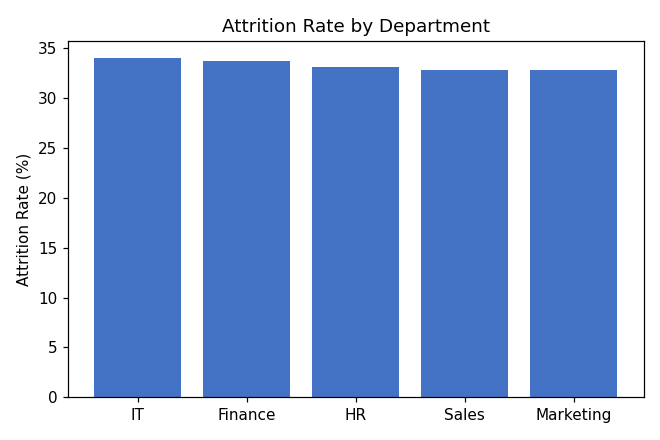

In [1]:
total = len(df)
terminated = (df['EmploymentStatus']=='Terminated').sum()
print(f"Overall attrition rate: {terminated}/{total} = {terminated/total:.2%}")

dept_attr = df.groupby('Department').apply(
    lambda g: pd.Series({'employees': len(g), 'terminated': (g['EmploymentStatus']=='Terminated').sum()})
)
dept_attr['attrition_rate'] = dept_attr['terminated'] / dept_attr['employees']
dept_attr = dept_attr.sort_values('attrition_rate', ascending=False)
print(dept_attr)

plt.figure(figsize=(6,4))
plt.bar(dept_attr.index, dept_attr['attrition_rate']*100, color='#4472C4')
plt.ylabel('Attrition Rate (%)')
plt.title('Attrition Rate by Department')
plt.tight_layout()
plt.savefig('chart_attrition_by_dept.png', dpi=110)
plt.show()

Attrition is close to 33% in every department (range: 32.8% to 34.0%). With about 10,000 employees per department, a difference of this size is close to what you'd expect from random chance alone — it doesn't look like one department has a real, meaningfully higher attrition problem than another.

### Average salary by department

              Salary     Bonus
Department                    
Finance     75827.67  10039.32
Sales       75122.68  10030.87
Marketing   74977.71  10005.98
IT          74929.82  10046.54
HR          74583.86  10023.16


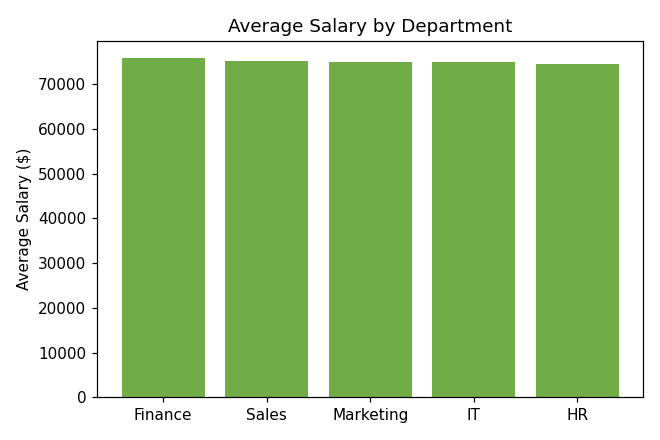

In [1]:
sal_dept = df.groupby('Department')[['Salary','Bonus']].mean().sort_values('Salary', ascending=False)
print(sal_dept.round(2))

plt.figure(figsize=(6,4))
plt.bar(sal_dept.index, sal_dept['Salary'], color='#70AD47')
plt.ylabel('Average Salary ($)')
plt.title('Average Salary by Department')
plt.tight_layout()
plt.savefig('chart_salary_by_dept.png', dpi=110)
plt.show()

Average salary is within about $1,250 of each other across all five departments (roughly 1.7% spread). No department stands out as paying meaningfully more or less.

### Performance rating vs salary

PerformanceRating
1    75214.65
2    75348.94
3    74903.57
4    75029.58
5    74953.15
Name: Salary, dtype: float64

Correlation: -0.0046


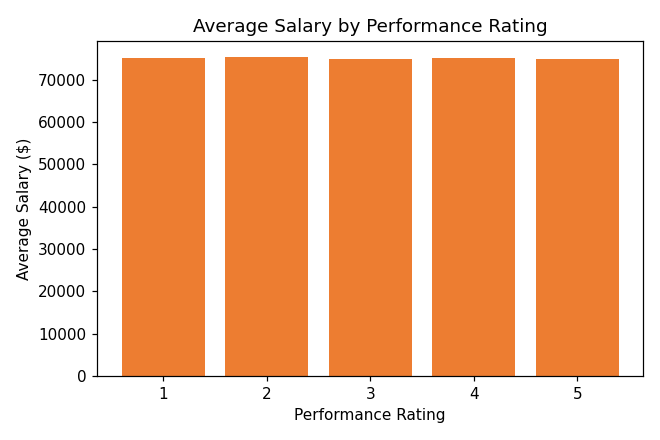

In [1]:
perf_sal = df.groupby('PerformanceRating')['Salary'].mean()
print(perf_sal.round(2))
print("\nCorrelation:", round(df['PerformanceRating'].corr(df['Salary']), 4))

plt.figure(figsize=(6,4))
plt.bar(perf_sal.index.astype(str), perf_sal.values, color='#ED7D31')
plt.xlabel('Performance Rating'); plt.ylabel('Average Salary ($)')
plt.title('Average Salary by Performance Rating')
plt.tight_layout()
plt.savefig('chart_perf_vs_salary.png', dpi=110)
plt.show()

Correlation is -0.005 — essentially zero. In this dataset, higher performance ratings are not associated with higher pay.

### Stress level vs absences and job satisfaction

In [1]:
print("Correlation StressLevelScore vs Absences:", round(df['StressLevelScore'].corr(df['Absences']), 4))
print("Correlation StressLevelScore vs JobSatisfactionScore:", round(df['StressLevelScore'].corr(df['JobSatisfactionScore']), 4))

Correlation StressLevelScore vs Absences: 0.0038
Correlation StressLevelScore vs JobSatisfactionScore: 0.0018


Both correlations are close to 0. Stress level doesn't move together with absences or job satisfaction here.

### Hire source vs tenure and performance

            YearsAtCompany  PerformanceRating
HireSource                                   
Referral             5.048              3.003
Recruiter            5.009              3.003
Walk-in              5.000              2.987
Job Board            4.952              2.997


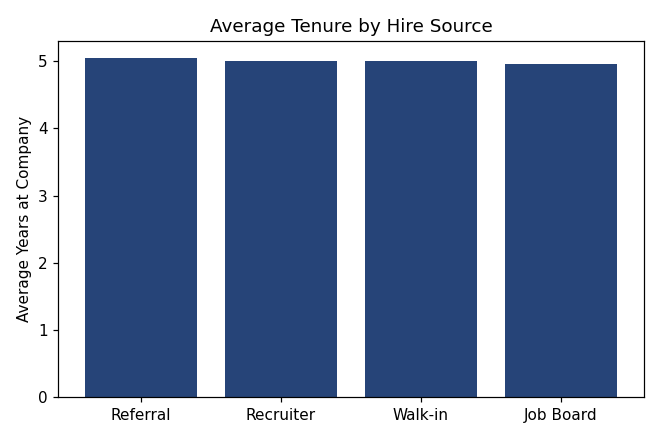

In [1]:
hire_src = df.groupby('HireSource')[['YearsAtCompany','PerformanceRating']].mean().sort_values('YearsAtCompany', ascending=False)
print(hire_src.round(3))

plt.figure(figsize=(6,4))
plt.bar(hire_src.index, hire_src['YearsAtCompany'], color='#264478')
plt.ylabel('Average Years at Company')
plt.title('Average Tenure by Hire Source')
plt.tight_layout()
plt.savefig('chart_tenure_by_hiresource.png', dpi=110)
plt.show()

Tenure and performance are almost identical across all four hire sources (within 0.1 years / 0.02 rating points). Hire source doesn't appear to matter here.

### Retention risk vs engagement and job satisfaction

               EmployeeEngagementScore  JobSatisfactionScore
RetentionRisk                                               
Low                              2.993                 3.000
Medium                           3.014                 2.988
High                             3.007                 2.987


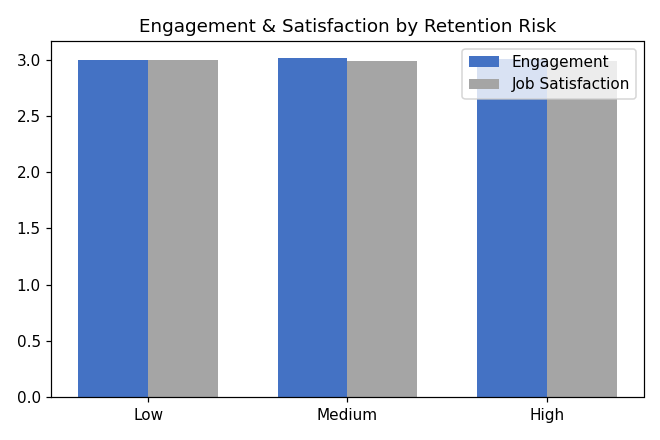

In [1]:
risk_eng = df.groupby('RetentionRisk')[['EmployeeEngagementScore','JobSatisfactionScore']].mean().reindex(['Low','Medium','High'])
print(risk_eng.round(3))

x = np.arange(3); w = 0.35
plt.figure(figsize=(6,4))
plt.bar(x-w/2, risk_eng['EmployeeEngagementScore'], width=w, label='Engagement', color='#4472C4')
plt.bar(x+w/2, risk_eng['JobSatisfactionScore'], width=w, label='Job Satisfaction', color='#A5A5A5')
plt.xticks(x, risk_eng.index)
plt.title('Engagement & Satisfaction by Retention Risk')
plt.legend()
plt.tight_layout()
plt.savefig('chart_risk_vs_engagement.png', dpi=110)
plt.show()

Employees labeled 'High' retention risk do not show lower engagement or satisfaction scores than 'Low' risk employees. The `RetentionRisk` label doesn't line up with the engagement/satisfaction data the way you'd expect.

### Gender pay gap

In [1]:
gender_sal = df.groupby('Gender')['Salary'].mean().sort_values(ascending=False)
print(gender_sal.round(2))

Gender
Male          75192.16
Female        75146.47
Non-Binary    74931.17
Name: Salary, dtype: float64


Less than 0.4% difference between the highest and lowest average salary by gender — no meaningful pay gap in this dataset.

### Promotions vs tenure

In [1]:
print("Correlation PromotionCount vs YearsAtCompany:", round(df['PromotionCount'].corr(df['YearsAtCompany']), 4))

Correlation PromotionCount vs YearsAtCompany: -0.0065


Correlation is essentially zero. Employees who have been at the company longer don't have more promotions on average, which is a bit surprising for real HR data — another sign this dataset was randomly generated rather than captured from an actual company.

### Recruitment cost and time-to-fill by department

In [1]:
recruit_dept = df.groupby('Department')[['RecruitmentCost','TimeToFillPosition']].mean().sort_values('RecruitmentCost', ascending=False)
print(recruit_dept.round(2))

            RecruitmentCost  TimeToFillPosition
Department                                     
Marketing           5491.17               32.40
HR                  5484.30               32.49
Finance             5482.02               32.48
Sales               5480.86               32.56
IT                  5447.40               32.49


Recruitment cost and time-to-fill are also nearly identical across departments.

## 7. Business Questions — Answers

1. **What is the overall attrition rate, and how does it differ by department?**
   Overall attrition is 33.3%. By department it ranges narrowly from 32.8% to 34.0% — no department stands out.

2. **Which departments have the highest average salary and bonus?**
   Finance is highest ($75,828 avg salary), HR is lowest ($74,584) — a gap of about 1.7%, not meaningful.

3. **Is PerformanceRating associated with Salary or Bonus?**
   No. Correlation is -0.005, essentially zero.

4. **Is StressLevelScore associated with Absences or JobSatisfactionScore?**
   No. Both correlations are close to 0.

5. **Which HireSource is associated with longer tenure or better performance?**
   None meaningfully — all four sources produce almost identical average tenure and performance.

6. **How does RetentionRisk relate to EmployeeEngagementScore and JobSatisfactionScore?**
   It doesn't. "High" risk employees don't show lower engagement or satisfaction than "Low" risk employees.

7. **Does average Salary differ by Gender?**
   No meaningful gap — under 0.4% difference between genders.

8. **How does PromotionCount relate to YearsAtCompany?**
   No relationship. Correlation is essentially zero.

9. **What is the average RecruitmentCost and TimeToFillPosition by department?**
   Nearly identical across all departments (~$5,450–$5,490, ~32.4–32.6 days).


## 8. Key Findings

- The dataset is internally clean in terms of structure (no duplicate rows, `EmployeeID` is a reliable key), but has some real data quality issues: 3,373 impossible ages at hire, ~48% of rows where completed projects exceed assigned projects, ~20,800 rows where promotion count and promotion date disagree, and a SupervisorID/Name field that isn't usable as a real key. All of these are flagged rather than silently fixed or deleted.
- Across every business question I checked — department, gender, hire source, performance, stress, retention risk label, promotions — I did not find a meaningful relationship with attrition, salary, or performance. Every group comparison came out close to equal, and every correlation came out close to zero.
- This strongly suggests the dataset was randomly generated for practice purposes rather than captured from a real company's HR system. That's fine for a portfolio project, but it means the honest conclusion is: **this dataset does not show a clear, actionable HR driver of attrition or performance**, and any dashboard built on it should present the numbers as they are rather than implying strong patterns that aren't actually there.


---
# Part 2 — Attrition Driver Analysis

Part 1 (sections 1–8) compared averages and correlations and concluded that nothing stood out. That conclusion was based on eyeballing differences. Here I test it properly, so the result is "I tested it and found nothing" instead of "it looked flat".

This part answers four questions:

1. What does the 33% attrition number actually mean, and how has it moved over time?
2. Is *any* column statistically linked to who leaves?
3. Can a model predict who leaves from the other columns?
4. Why do people leave, and how complete is that information?

## 9. Setup

In [2]:
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Reload the cleaned file so this part does not depend on variables from Part 1
hr = pd.read_csv('HR_cleaned_data.csv',
                 parse_dates=['DateOfHire', 'DateOfBirth', 'TerminationDate', 'LastPromotionDate'])

# Leaver = Terminated. Active and On Leave employees are both treated as "stayed".
hr['Left'] = (hr['EmploymentStatus'] == 'Terminated').astype(int)

print(hr.shape)
print(hr['EmploymentStatus'].value_counts())

(50000, 42)
EmploymentStatus
On Leave      16703
Active        16669
Terminated    16628
Name: count, dtype: int64


## 10. What does the 33% attrition rate mean?

The dashboards show an attrition rate of 33.26%. That is the share of *everyone in the file* who has ever left, across ten years of hiring. It is not a yearly rate, so it can't be compared with the 10–15% annual figures that HR teams usually quote.

To get a yearly rate I divide the people who left in a year by the headcount at the start of that year (hired before 1 January and not yet gone).

 Year  OpeningHeadcount  Exits  ExitRate
 2016              4575    260       5.7
 2017              9283    494       5.3
 2018             13787    699       5.1
 2019             18142    972       5.4
 2020             22109   1331       6.0
 2021             25717   1659       6.5
 2022             29138   2274       7.8
 2023             31842   3119       9.8
 2024             33693   4933      14.6

Last termination date in the file: 2025-01-30
Hires per year, min and max: 4647 and 5080


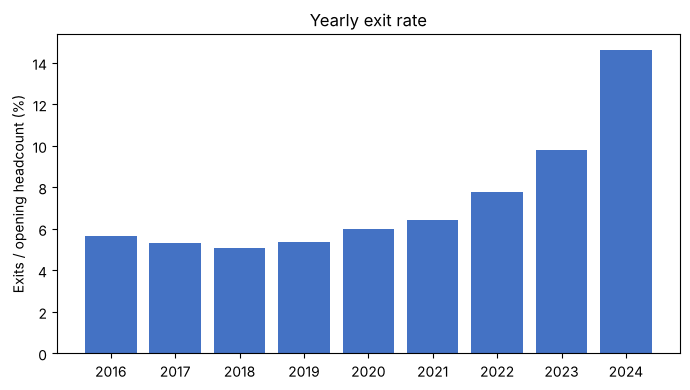

In [3]:
rows = []
for year in range(2016, 2025):
    start = pd.Timestamp(year, 1, 1)
    opening = ((hr['DateOfHire'] < start) &
               (hr['TerminationDate'].isna() | (hr['TerminationDate'] >= start))).sum()
    exits = (hr['TerminationDate'].dt.year == year).sum()
    rows.append((year, opening, exits, exits / opening))

yearly = pd.DataFrame(rows, columns=['Year', 'OpeningHeadcount', 'Exits', 'ExitRate'])
print(yearly.assign(ExitRate=(yearly['ExitRate'] * 100).round(1)).to_string(index=False))

print("\nLast termination date in the file:", hr['TerminationDate'].max().date())
print("Hires per year, min and max:",
      hr.groupby(hr['DateOfHire'].dt.year).size().loc[2015:2024].min(), "and",
      hr.groupby(hr['DateOfHire'].dt.year).size().loc[2015:2024].max())

plt.figure(figsize=(7, 4))
plt.bar(yearly['Year'].astype(str), yearly['ExitRate'] * 100, color='#4472C4')
plt.ylabel('Exits / opening headcount (%)')
plt.title('Yearly exit rate')
plt.tight_layout()
plt.savefig('chart_exit_rate_by_year.png', dpi=110)
plt.show()

Hiring is steady (about 5,000 people a year), yet the yearly exit rate climbs from about 5% in 2016 to about 15% in 2024. This is the only pattern in the dataset that is not flat.

I'm treating it with caution. The file stops on 30 January 2025, so 2025 is excluded because it holds one month of data. Also, termination dates look like they were spread between each person's hire date and the end of the file. If so, later years collect more exits by construction. Real data would need a check with the HR team on whether this rise is genuine.

## 11. Is any column linked to who leaves?

I tested every available factor against `Left` (Terminated vs everyone else):

- Numeric columns (21): Mann-Whitney U test, which doesn't assume a bell-shaped distribution.
- Category columns (9): chi-square test of independence.
- `JobTitle` is left out because it has 639 values spread across about 50,000 rows.

Running 30 tests means that about 1–2 would look "significant" by luck alone at the usual 0.05 cut-off. So I also apply a Bonferroni correction: the cut-off becomes 0.05 divided by the number of tests.

Tests run: 30 | Bonferroni cut-off: 0.0017
Significant at 0.05: 0
Significant after Bonferroni: 0

                    Factor         Test  p_value  Significant_at_0.05  Significant_after_Bonferroni
   EmployeeEngagementScore Mann-Whitney   0.0633                False                         False
             RetentionRisk   Chi-square   0.1962                False                         False
PerformanceImprovementPlan   Chi-square   0.2453                False                         False
          StressLevelScore Mann-Whitney   0.2644                False                         False
          ProjectsAssigned Mann-Whitney   0.2982                False                         False
                Department   Chi-square   0.2988                False                         False
    YearsSinceLastTraining Mann-Whitney   0.3083                False                         False
             OvertimeHours Mann-Whitney   0.3971                False                         False


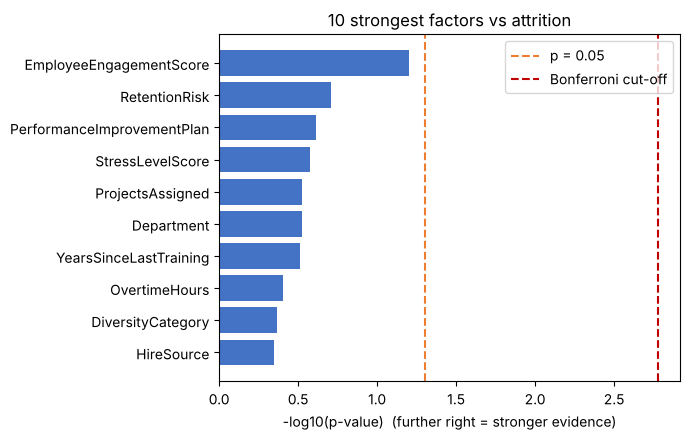

In [4]:
numeric_cols = ['Salary', 'Bonus', 'YearsAtCompany', 'YearsInCurrentRole', 'TrainingHours',
                'OvertimeHours', 'Absences', 'EmployeeEngagementScore', 'TeamSize',
                'PromotionCount', 'WorkFromHomeDays', 'YearsSinceLastTraining',
                'JobSatisfactionScore', 'SkillsAssessmentScore', 'RecruitmentCost',
                'TimeToFillPosition', 'WorkHoursPerWeek', 'StressLevelScore',
                'PerformanceRating', 'ProjectsAssigned', 'ProjectsCompleted']
categorical_cols = ['Gender', 'Department', 'SupervisorLevel', 'HireSource',
                    'PerformanceImprovementPlan', 'RetentionRisk', 'DiversityCategory',
                    'InternalPromotion', 'SeniorLeader']

results = []
for c in numeric_cols:
    _, p = stats.mannwhitneyu(hr.loc[hr['Left'] == 1, c], hr.loc[hr['Left'] == 0, c])
    results.append((c, 'Mann-Whitney', p))
for c in categorical_cols:
    _, p, _, _ = stats.chi2_contingency(pd.crosstab(hr[c], hr['Left']))
    results.append((c, 'Chi-square', p))

tests = pd.DataFrame(results, columns=['Factor', 'Test', 'p_value']).sort_values('p_value').reset_index(drop=True)
bonferroni = 0.05 / len(tests)
tests['Significant_at_0.05'] = tests['p_value'] < 0.05
tests['Significant_after_Bonferroni'] = tests['p_value'] < bonferroni

print("Tests run:", len(tests), "| Bonferroni cut-off:", round(bonferroni, 4))
print("Significant at 0.05:", tests['Significant_at_0.05'].sum())
print("Significant after Bonferroni:", tests['Significant_after_Bonferroni'].sum())
print()
print(tests.head(8).round(4).to_string(index=False))

top = tests.head(10).iloc[::-1]
plt.figure(figsize=(7, 4.5))
plt.barh(top['Factor'], -np.log10(top['p_value']), color='#4472C4')
plt.axvline(-np.log10(0.05), color='#ED7D31', linestyle='--', label='p = 0.05')
plt.axvline(-np.log10(bonferroni), color='#C00000', linestyle='--', label='Bonferroni cut-off')
plt.xlabel('-log10(p-value)  (further right = stronger evidence)')
plt.title('10 strongest factors vs attrition')
plt.legend()
plt.tight_layout()
plt.savefig('chart_driver_tests.png', dpi=110)
plt.show()

Not one of the 30 factors is linked to attrition, even before correcting for multiple tests. The closest is `EmployeeEngagementScore` (p ≈ 0.06), and it does not reach 0.05.

This is also a meaningful "no", because the sample is large enough to see small differences. The next cell works out how small.

In [5]:
p0 = hr['Left'].mean()
n_dept = hr['Department'].value_counts().min()

# Smallest gap between two groups of this size that a test would catch 80% of the time
mde = (1.96 + 0.84) * np.sqrt(2 * p0 * (1 - p0) / n_dept)
print(f"Overall attrition: {p0:.1%}")
print(f"Smallest department size: {n_dept:,}")
print(f"A department-to-department gap of about {mde * 100:.1f} percentage points or more would have been detected.")
print("Actual spread between departments:",
      f"{hr.groupby('Department')['Left'].mean().max() - hr.groupby('Department')['Left'].mean().min():.1%}")

Overall attrition: 33.3%
Smallest department size: 9,932
A department-to-department gap of about 1.9 percentage points or more would have been detected.
Actual spread between departments: 1.2%


## 12. Can a model predict who leaves?

A single column may show nothing while a combination of columns does. To check, I trained two models on all 30 factors and measured how well they separate leavers from stayers using 5-fold cross-validation and AUC. An AUC of 0.50 equals a coin flip and 1.00 is perfect.

In [6]:
X = pd.concat([hr[numeric_cols],
               pd.get_dummies(hr[categorical_cols], drop_first=True).astype(int)], axis=1)
y = hr['Left']

logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
forest = RandomForestClassifier(n_estimators=100, max_depth=8, n_jobs=-1, random_state=42)

auc_logit = cross_val_score(logit, X, y, cv=5, scoring='roc_auc')
auc_forest = cross_val_score(forest, X, y, cv=5, scoring='roc_auc')

print("Logistic regression AUC per fold:", auc_logit.round(3), "| mean:", auc_logit.mean().round(3))
print("Random forest AUC per fold:     ", auc_forest.round(3), "| mean:", auc_forest.mean().round(3))
print("Always guessing 'stayed' is right", f"{1 - y.mean():.1%}", "of the time, so accuracy would be misleading here.")

Logistic regression AUC per fold: [0.496 0.494 0.5   0.49  0.5  ] | mean: 0.496
Random forest AUC per fold:      [0.498 0.501 0.495 0.5   0.503] | mean: 0.499
Always guessing 'stayed' is right 66.7% of the time, so accuracy would be misleading here.


Both models score about 0.50, the same as guessing. Even combined, the columns carry no information about who leaves. Predicting attrition from this data is not possible.

## 13. The Retention Risk label

`RetentionRisk` is the one column that is *supposed* to predict leaving. This is how it compares with what actually happened.

In [7]:
risk = hr.groupby('RetentionRisk')['Left'].agg(['size', 'mean']).reindex(['Low', 'Medium', 'High'])
risk['mean'] = (risk['mean'] * 100).round(2)
risk.columns = ['Employees', 'Attrition_%']
print(risk)

_, p, _, _ = stats.chi2_contingency(pd.crosstab(hr['RetentionRisk'], hr['Left']))
print("\nChi-square p-value:", round(p, 3))

               Employees  Attrition_%
RetentionRisk                        
Low                16572        32.76
Medium             16749        33.69
High               16679        33.32

Chi-square p-value: 0.196


"High" risk employees left at 33.3% and "Low" risk employees at 32.8%, about the same, and the difference is not statistically significant. If this label were used to decide who gets retention attention, it would not target the right people.

## 14. Why do people leave?

Each leaver has a `ReasonForLeaving`. I check how complete it is and how it splits.

ReasonForLeaving
Not recorded    4263
Layoff          4177
Retirement      4144
Resignation     4044
Name: count, dtype: int64

ReasonForLeaving
Not recorded    25.6%
Layoff          25.1%
Retirement      24.9%
Resignation     24.3%
Name: count, dtype: str

Reason mix by department (% of that department's leavers):
ReasonForLeaving  Layoff  Not recorded  Resignation  Retirement
Department                                                     
Finance             25.7          25.7         23.3        25.4
HR                  25.1          24.9         24.4        25.6
IT                  25.0          25.7         24.0        25.3
Marketing           24.5          26.0         24.5        25.1
Sales               25.4          25.9         25.5        23.1


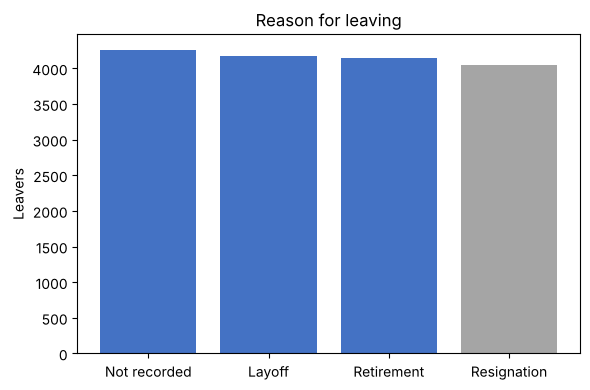

In [8]:
leavers = hr[hr['Left'] == 1].copy()
reasons = leavers['ReasonForLeaving'].fillna('Not recorded').value_counts()
print(reasons)
print()
print((reasons / len(leavers) * 100).round(1).astype(str) + '%')

by_dept = pd.crosstab(leavers['Department'], leavers['ReasonForLeaving'].fillna('Not recorded'), normalize='index') * 100
print("\nReason mix by department (% of that department's leavers):")
print(by_dept.round(1))

plt.figure(figsize=(6, 4))
plt.bar(reasons.index, reasons.values, color=['#4472C4', '#4472C4', '#4472C4', '#A5A5A5'][:len(reasons)])
plt.ylabel('Leavers')
plt.title('Reason for leaving')
plt.tight_layout()
plt.savefig('chart_reason_for_leaving.png', dpi=110)
plt.show()

Layoff, Retirement and Resignation each account for about a quarter of leavers, in every department. For about 26% of leavers, no reason is recorded. Resignation is the reason HR can influence, but it is only one-quarter of exits here, so retention actions would address a small slice of the problem.

One more thing doesn't add up: the reason "Retirement" is checked against age below.

In [9]:
leavers['AgeAtExit'] = (leavers['TerminationDate'] - leavers['DateOfBirth']).dt.days / 365.25
retired = leavers[leavers['ReasonForLeaving'] == 'Retirement']
print("Median age at exit, people marked 'Retirement':", round(retired['AgeAtExit'].median(), 1))
print("Share of 'Retirement' exits under age 55:", f"{(retired['AgeAtExit'] < 55).mean():.1%}")
print("Median age at exit, all other leavers:        ", round(leavers.loc[leavers['ReasonForLeaving'] != 'Retirement', 'AgeAtExit'].median(), 1))

Median age at exit, people marked 'Retirement': 39.3
Share of 'Retirement' exits under age 55: 81.8%
Median age at exit, all other leavers:         39.6


Retirees have the same median age (about 39) as everyone else, and about 82% of "Retirement" exits are under 55. So the reason field doesn't line up with age either. This is a sixth data quality issue.

## 15. A new data quality check: tenure vs dates

In Part 1 I checked age at hire, projects and promotions. I had not checked whether `YearsAtCompany` agrees with the dates. I rebuild tenure from `DateOfHire` and the termination date. For people still employed, I use the last date in the file as "today".

In [10]:
snapshot = hr['TerminationDate'].max()
hr['TenureFromDates'] = (hr['TerminationDate'].fillna(snapshot) - hr['DateOfHire']).dt.days / 365.25

print("Correlation between YearsAtCompany and tenure from dates:",
      round(hr['YearsAtCompany'].corr(hr['TenureFromDates']), 3))
print("Rows where the two differ by more than 2 years:",
      f"{(hr['YearsAtCompany'] - hr['TenureFromDates']).abs().gt(2).mean():.1%}")

leavers = hr[hr['Left'] == 1]
print("\nTenure at exit (years), from dates:")
print(leavers['TenureFromDates'].describe().round(2))
print("Left within 6 months of hire:", f"{(leavers['TenureFromDates'] < 0.5).mean():.1%}")
print("Left within 1 year of hire:  ", f"{(leavers['TenureFromDates'] < 1).mean():.1%}")

Correlation between YearsAtCompany and tenure from dates: 0.005
Rows where the two differ by more than 2 years: 65.7%

Tenure at exit (years), from dates:
count    16628.00
mean         2.50
std          2.21
min          0.00
25%          0.68
50%          1.87
75%          3.82
max          9.93
Name: TenureFromDates, dtype: float64
Left within 6 months of hire: 20.2%
Left within 1 year of hire:   33.1%


`YearsAtCompany` has no relationship with the dates (correlation about 0.005), and about two-thirds of rows differ by more than 2 years. So it can't be trusted as a tenure measure. This is a fifth data quality issue, and it matters because tenure is a standard attrition factor. Using the date-based tenure, a typical leaver left after about 1.9 years, and 1 in 5 left within 6 months.

I'm flagging this rather than overwriting it, in line with how I treated the other issues.

## 16. Key Findings — Part 2

- **The 33% figure is cumulative, not yearly.** It covers ten years of hires. Measured yearly, exits rise from about 5% (2016) to about 15% (2024). That climb may be an artifact of how the dates were built, so it should be confirmed before anyone acts on it.
- **No factor is linked to attrition.** 0 of 30 tests are significant, even before correction, and the sample can detect gaps of about 2 percentage points. This makes the "no driver" conclusion a tested result.
- **Attrition can't be predicted from this data.** Logistic regression and random forest both score an AUC of about 0.50.
- **The `RetentionRisk` label has no link to leaving.** High-risk and low-risk employees left at the same rate.
- **Reasons for leaving are evenly split** (about 25% each for layoff, retirement and resignation) and are missing for about 26% of leavers.
- **Two new data quality issues:** `YearsAtCompany` doesn't agree with `DateOfHire` and the termination date, and "Retirement" exits have the same median age (about 39) as every other exit.

**What I'd recommend if this were real HR data**

1. Don't use `RetentionRisk` to target retention effort until it is validated against actual exits.
2. Make `ReasonForLeaving` mandatory on exit, because a quarter of it is blank today.
3. Report attrition as a yearly rate on opening headcount, not as a share of everyone ever hired.
4. Fix how tenure is recorded, so `YearsAtCompany` and the dates agree.
5. Ask the data owner why exits rise so sharply in later years before drawing conclusions.